# 11. Fitting a straight line

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1, 3 and 4

**Reading:** Taylor, ch. 8 · Bevington & Robinson, ch. 6 · Fornasini, ch.
10.3–10.4 · Rouaud, ch. II.C

Very often a quantity is obtained not from a single pair of measurements
but from the slope or intercept of a graph: a spring constant from
extension against load, a resistance from voltage against current, a rate
constant from the logarithm of concentration against time. Fitting uses all
the data at once, exposes points and trends that do not belong, and, done
properly, returns the uncertainty of the slope and intercept.

In this notebook we

1. derive the least-squares line and the uncertainties of its parameters;
2. fit a data set and read the residuals;
3. extend the method to points with different error bars and meet $\chi^2$;
4. verify the quoted uncertainties by simulation;
5. list the pitfalls that the advanced notebook
   [Chapter 13](13_fit_parameter_covariance.ipynb) treats in depth.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(4)

## 11.1 The principle of least squares

We have $N$ points $(x_i, y_i)$ and a model $y = a + bx$. We assume, for
now, that

* the $x_i$ are known much more precisely than the $y_i$;
* every $y_i$ has the same standard uncertainty $\sigma$;
* the errors of different points are independent.

The vertical distance of a point from the line is the **residual**
$r_i = y_i - a - bx_i$. The best line is taken to be the one that minimises
the sum of squared residuals,

$$ S(a, b) = \sum_{i=1}^{N} (y_i - a - b x_i)^2 . $$

(For normally distributed errors this is also the line that makes the
observed data most probable.) Setting the two partial derivatives to zero,

$$ \frac{\partial S}{\partial a} = -2\sum_i (y_i - a - bx_i) = 0, \qquad
   \frac{\partial S}{\partial b} = -2\sum_i x_i (y_i - a - bx_i) = 0 . $$

The first equation gives $a = \bar y - b\bar x$: the best line passes
through the centroid $(\bar x, \bar y)$ of the data. Substituting into the
second,

$$ b = \frac{S_{xy}}{S_{xx}}, \qquad a = \bar y - b\,\bar x, $$

with the abbreviations

$$ S_{xx} = \sum_i (x_i - \bar x)^2, \qquad S_{xy} = \sum_i (x_i - \bar x)(y_i - \bar y) . $$

## 11.2 Uncertainties of slope and intercept

The slope can be written as $b = \sum_i k_i y_i$ with
$k_i = (x_i - \bar x)/S_{xx}$ (the term with $\bar y$ drops out because
$\sum_i (x_i - \bar x) = 0$). It is a linear function of the $y_i$, so the
propagation law of Chapter 3 applies exactly:

$$ u_b^2 = \sum_i k_i^2\,\sigma^2 = \frac{\sigma^2}{S_{xx}} . $$

In the same way $a = \sum_i \left[\tfrac1N - \bar x\,k_i\right] y_i$, which gives

$$ u_a^2 = \sigma^2\left(\frac{1}{N} + \frac{\bar x^2}{S_{xx}}\right) . $$

Two practical lessons are contained in $u_b = \sigma/\sqrt{S_{xx}}$. The
slope improves with more points, and it improves faster by *spreading the
points over a wide range of $x$*, since $S_{xx}$ grows with the square of
the range.

If $\sigma$ is not known in advance, it is estimated from the scatter of
the points about the line,

$$ s^2 = \frac{1}{N-2}\sum_i r_i^2 . $$

The divisor is $N-2$ because two parameters were fitted. (Two points
define a line exactly and tell nothing about the scatter.)

## 11.3 Example: a spring

Known masses are hung from a spring and the position of a pointer is read
from a scale. The load $F = mg$ is known precisely; the position reading is
good to about a millimetre. We therefore put the load on the horizontal
axis and fit

$$ x = x_0 + \frac{1}{k}\,F . $$

The slope is the compliance $1/k$. The data below are simulated, with a
true spring constant of 25.0 N/m, so that we can judge the outcome.

In [2]:
g = 9.81
k_true, x0_true, sigma_x = 25.0, 0.0320, 0.0010       # N/m, m, m
mass = np.arange(50, 501, 50) * 1e-3                   # kg
F = mass * g                                           # N
x = x0_true + F / k_true + rng.normal(0, sigma_x, F.size)   # pointer position, m

fit = ep.linear_fit(F, x)
print(fit)

intercept = 0.0321935 +/- 0.00071
slope     = 0.0398545 +/- 0.00023
correlation(intercept, slope) = -0.886
residual standard deviation = 0.00104  (dof = 8)


The spring constant is $k = 1/b$, and by the power rule its relative
uncertainty equals that of the slope.

In [3]:
k = 1 / fit.slope
u_k = k * fit.u_slope / fit.slope
print("k   =", ep.format_result(k, u_k, "N/m"), f"   (true value {k_true})")
print("x0  =", ep.format_result(fit.intercept * 1e3, fit.u_intercept * 1e3, "mm"),
      f"   (true value {x0_true * 1e3:.1f})")
print(f"scatter about the line: s = {fit.residual_std * 1e3:.2f} mm   (true sigma {sigma_x * 1e3:.1f} mm)")

k   = 25.09 ± 0.15 N/m    (true value 25.0)
x0  = 32.19 ± 0.71 mm    (true value 32.0)
scatter about the line: s = 1.04 mm   (true sigma 1.0 mm)


### Always plot the residuals

A fit returns numbers whether or not the model is appropriate. The plot
that tells the two cases apart is the plot of residuals against $x$. For a
correct model they scatter randomly about zero with no pattern. The lower
panels below show a spring that stiffens at large extension (a small
quadratic term in the extension): the straight-line fit still looks
acceptable in panel (c), but the residuals in panel (d) form an arch, a
sure sign that the model is missing something.

stiffening spring: R^2 of the straight-line fit = 0.9980


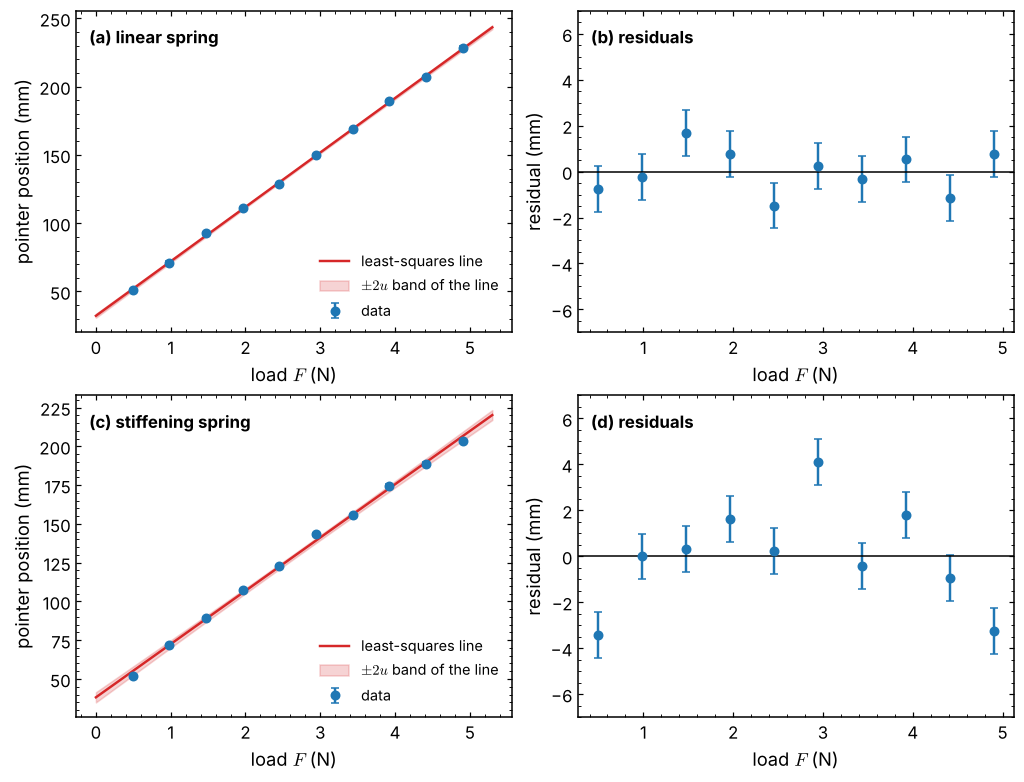

In [4]:
# a second, slightly nonlinear spring, fitted with the same straight line
x_nl = x0_true + F / k_true - 0.024 * (F / F.max())**2 + rng.normal(0, sigma_x, F.size)
fit_nl = ep.linear_fit(F, x_nl)
R2 = 1 - np.sum(fit_nl.residuals**2) / np.sum((x_nl - x_nl.mean())**2)
print(f"stiffening spring: R^2 of the straight-line fit = {R2:.4f}")
Fg = np.linspace(0, 5.3, 100)

fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.0))
for row, (xx, ff, title) in enumerate(((x, fit, "linear spring"),
                                       (x_nl, fit_nl, "stiffening spring"))):
    ax = axes[row, 0]
    yg, ug = ff.predict(Fg)
    ax.errorbar(F, xx * 1e3, yerr=sigma_x * 1e3, fmt="o", color="C0", label="data")
    ax.plot(Fg, yg * 1e3, "C3", label="least-squares line")
    ax.fill_between(Fg, (yg - 2 * ug) * 1e3, (yg + 2 * ug) * 1e3, color="C3", alpha=0.2,
                    label="$\\pm 2u$ band of the line")
    ax.set_xlabel("load $F$ (N)"); ax.set_ylabel("pointer position (mm)")
    ax.legend(loc="lower right"); ep.panel_label(ax, f"({'ac'[row]}) {title}")
    ax = axes[row, 1]
    ax.errorbar(F, ff.residuals * 1e3, yerr=sigma_x * 1e3, fmt="o", color="C0")
    ax.axhline(0, color="k", lw=1)
    ax.set_ylim(-7, 7)
    ax.set_xlabel("load $F$ (N)"); ax.set_ylabel("residual (mm)")
    ep.panel_label(ax, f"({'bd'[row]}) residuals")
plt.show()

The shaded band is the uncertainty of the fitted line itself. It is
narrowest near the centroid of the data and widens towards the ends and
beyond: **extrapolation is always less certain than interpolation.** The
band is computed by `fit.predict`, which accounts for the fact that slope
and intercept, having been determined from the same data, are not
independent of each other. Why that matters is the subject of
[Chapter 13](13_fit_parameter_covariance.ipynb).

## 11.4 Points with different error bars: weighted fits and $\chi^2$

If the points have different, known uncertainties $\sigma_i$, a precise
point should pull the line harder than an imprecise one. As with the
weighted mean (Section 4.6), each squared residual is divided by its
variance, and we minimise

$$ \chi^2(a, b) = \sum_{i=1}^{N} \frac{(y_i - a - bx_i)^2}{\sigma_i^2} . $$

The solution has the same form as before with every sum weighted by
$w_i = 1/\sigma_i^2$. For instance, with
$\bar x_w = \sum w_i x_i / \sum w_i$,

$$ b = \frac{\sum_i w_i (x_i - \bar x_w)(y_i - \bar y_w)}{\sum_i w_i (x_i - \bar x_w)^2},
   \qquad u_b^2 = \frac{1}{\sum_i w_i (x_i - \bar x_w)^2} . $$

The minimum value of $\chi^2$ is a measure of the **goodness of fit**. Each
term is about one if the model is right and the error bars are right, and
two parameters have been adjusted, so we expect

$$ \chi^2_\text{min} \approx N - 2 \equiv \nu , \qquad\text{or}\qquad \chi^2_\nu = \chi^2_\text{min}/\nu \approx 1 , $$

with a typical spread of $\sqrt{2/\nu}$ in $\chi^2_\nu$.

| Observation | Likely meaning |
|---|---|
| $\chi^2_\nu \approx 1$ | model and error bars are consistent with the data |
| $\chi^2_\nu \gg 1$ | wrong model, or error bars underestimated |
| $\chi^2_\nu \ll 1$ | error bars overestimated (or correlated) |

Example: a rate of gas production measured at eight temperatures, with a
detector whose noise grows with the signal.

In [5]:
T = np.linspace(20, 90, 8)                       # deg C
sigma_y = 0.05 + 0.04 * np.arange(8)             # error bar grows along the series
y = 1.2 + 0.085 * T + rng.normal(0, sigma_y)

fit_w = ep.linear_fit(T, y, sigma=sigma_y)
fit_u = ep.linear_fit(T, y)
print("weighted fit\n", fit_w, sep="")
print("\nunweighted fit of the same data\n", fit_u, sep="")
print("\ntrue values: intercept 1.2, slope 0.085")

weighted fit
intercept = 1.18684 +/- 0.082
slope     = 0.0843827 +/- 0.0024
correlation(intercept, slope) = -0.883
chi2 / dof = 6.65 / 6 = 1.11

unweighted fit of the same data
intercept = 1.31533 +/- 0.21
slope     = 0.0817578 +/- 0.0036
correlation(intercept, slope) = -0.923
residual standard deviation = 0.233  (dof = 6)

true values: intercept 1.2, slope 0.085


Both fits are consistent with the true values. The weighted fit has the
smaller uncertainties, because it relies mostly on the precise points at
low temperature, and its $\chi^2_\nu$ confirms that the scatter is of the
size the error bars predict.

## 11.5 Checking the uncertainties by simulation

Is $u_b$ really the standard deviation of the slope? As in Chapter 4 we
can repeat the whole experiment on the computer. If the formula is right,
the fitted slopes of many simulated spring experiments scatter with
standard deviation $u_b$, and the interval $b \pm u_b$ contains the true
slope in about 68 % of them.

In [6]:
n_rep = 5000
slopes = np.empty(n_rep); u_slopes = np.empty(n_rep)
for i in range(n_rep):
    xi = x0_true + F / k_true + rng.normal(0, sigma_x, F.size)
    f_i = ep.linear_fit(F, xi)
    slopes[i], u_slopes[i] = f_i.slope, f_i.u_slope

b_true = 1 / k_true
print(f"standard deviation of the fitted slopes : {slopes.std():.3e} m/N")
print(f"formula sigma / sqrt(Sxx)               : {sigma_x / np.sqrt(np.sum((F - F.mean())**2)):.3e} m/N")
print(f"typical quoted u_b (from the scatter)   : {np.median(u_slopes):.3e} m/N")
print(f"fraction of fits with |b - b_true| < u_b: {np.mean(np.abs(slopes - b_true) < u_slopes):.3f}")

standard deviation of the fitted slopes : 2.231e-04 m/N
formula sigma / sqrt(Sxx)               : 2.245e-04 m/N
typical quoted u_b (from the scatter)   : 2.157e-04 m/N
fraction of fits with |b - b_true| < u_b: 0.662


The spread of the slopes matches the formula. The coverage, about 66 %,
falls a little short of 68 % for the reason met in Section 4.4: with ten
points the scatter $s$ is estimated from only eight degrees of freedom.
Student's $t$ with $\nu = N - 2$ repairs this exactly.

## 11.6 Pitfalls

* **Which variable goes on which axis.** Ordinary least squares assumes the
  uncertainty is in $y$ only. Put the more precisely known variable on the
  horizontal axis. If both are uncertain, see
  [Chapter 13](13_fit_parameter_covariance.ipynb).
* **Slope and intercept are correlated.** They come from the same data. Any
  quantity computed from both (a predicted value, an $x$-intercept) needs
  their covariance, not just $u_a$ and $u_b$.
* **Transforming the data changes the weights.** Taking logarithms to turn an
  exponential into a straight line also transforms the error bars:
  $u_{\ln y} = u_y/y$. Equal error bars in $y$ become very unequal ones in
  $\ln y$, and an unweighted fit of the transformed data is then wrong.
* **A high correlation coefficient proves little.** The stiffening spring of
  Section 11.3 has $R^2 > 0.99$ (printed above the figure). Residuals and $\chi^2$ are the tests of a
  model, not $R^2$.
* **Outliers.** One bad point far from the centroid can turn the line. Do
  not delete points because they look wrong; find out why they are wrong,
  or keep them.

## Summary

* Least squares gives $b = S_{xy}/S_{xx}$ and $a = \bar y - b\bar x$, with
  $u_b = \sigma/\sqrt{S_{xx}}$ and
  $u_a = \sigma\sqrt{1/N + \bar x^2/S_{xx}}$.
* A wide range of $x$ is the most effective way to a precise slope.
* With known, unequal error bars, weight each point by $1/\sigma_i^2$ and
  check that $\chi^2 \approx N - 2$.
* Plot the residuals. Always.

## Exercises

1. Refit the spring data using only the five smallest loads. By what factor
   does $u_k$ grow, and why is it much more than $\sqrt 2$?
2. In Section 11.4, deliberately halve all error bars and refit. What happens
   to the parameter uncertainties and to $\chi^2_\nu$? What would you conclude
   if you saw this in a real experiment?
3. The voltage across a discharging capacitor is $V = V_0 e^{-t/\tau}$.
   Simulate ten points with the same absolute noise on $V$, and fit
   $\ln V$ against $t$ (a) unweighted and (b) weighted with
   $\sigma_{\ln V} = \sigma_V/V$. Repeat many times. Which estimate of $\tau$
   scatters less?
4. Use `fit.predict` to find the pointer position expected for a load of
   10 N and its uncertainty. Why should this number be treated with caution
   beyond its quoted uncertainty?

---

**Previous:** [10. Monte Carlo methods](../part2_probability_statistics/10_monte_carlo_methods.ipynb) &nbsp;·&nbsp; **Next:** [12. Covariance and the limits of linearisation](12_covariance_and_limits_of_linearisation.ipynb)